In [2]:
import os, time, warnings, joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import ParameterGrid
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

In [3]:
SKIP_DIRS = {".git", ".ipynb_checkpoints", "__pycache__", "node_modules",
             ".venv", "venv", "env", ".idea", ".vscode"}

def find_file(filename, required_cols=None, prefer=("raw",), must_exist=True):
    """Cari `filename` di folder kerja, lalu naik ke folder induk sampai root repo (.git).
    Jika required_cols diberikan, hanya file yang header-nya memuat kolom tsb yang dianggap cocok."""
    start = Path.cwd().resolve()
    roots = []
    for p in [start, *start.parents]:
        roots.append(p)
        if (p / ".git").exists() or len(roots) >= 4:
            break

    for root in roots:
        matches = []
        for dirpath, dirnames, filenames in os.walk(root):
            dirnames[:] = [d for d in dirnames if d not in SKIP_DIRS]
            if filename in filenames:
                path = Path(dirpath) / filename
                if required_cols:
                    try:
                        cols = pd.read_csv(path, nrows=0).columns
                    except Exception:
                        continue
                    if not set(required_cols).issubset(cols):
                        continue
                matches.append(path)
        if matches:
            matches.sort(key=lambda p: (not any(k in p.parts for k in prefer), len(p.parts)))
            if len(matches) > 1:
                print(f"Ditemukan {len(matches)} kandidat untuk '{filename}', dipakai yang pertama:")
                for m in matches:
                    print("   -", m)
            return matches[0]

    if must_exist:
        raise FileNotFoundError(
            f"'{filename}' tidak ditemukan. Dicari di: {[str(r) for r in roots]}. "
            "Pastikan notebook dijalankan dari dalam folder repo.")
    return None

DATA_PATH = find_file("train.csv", required_cols=["date", "food_waste_kg"], prefer=("raw",))
print("Dataset mentah dipakai:", DATA_PATH)

# ---------- Konfigurasi ----------
TARGET = "food_waste_kg"
SEED = 42
TEST_FRAC = 0.20        # 20% data terbaru -> test (sama dengan split sebelumnya: 728 train / 183 test)
VAL_FRAC = 0.15         # 15% data terbaru dari train -> validation (untuk tuning)
USE_LAG = False         # lag-1 target hanya bernilai kecil; aktifkan hanya jika ketersediaannya bisa dijustifikasi
CLIP_MEALS = False      # Robust: apakah meals_served ikut di-clip
SEEDS = [0, 1, 2, 3, 4] # seed untuk evaluasi akhir RF

# Folder output ditaruh di root repo (bukan di folder notebooks), dibuat otomatis
OUT_ROOT = Path.cwd().resolve()
for p in [OUT_ROOT, *OUT_ROOT.parents]:
    if (p / ".git").exists():
        OUT_ROOT = p
        break
RESULTS_DIR = OUT_ROOT / "results"
MODELS_DIR = OUT_ROOT / "models"
RESULTS_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

Dataset mentah dipakai: D:\SDT\Project Sistem Cerdas\foodsafe\foodSaveProject\dataset\raw\train.csv


In [4]:
df = pd.read_csv(DATA_PATH)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["date", "ID"]).reset_index(drop=True)

print("Shape:", df.shape)
print("Rentang tanggal:", df["date"].min().date(), "->", df["date"].max().date())
print("\nMissing value:\n", df.isna().sum()[df.isna().sum() > 0])
print("\nDuplikat persis (tanpa ID):", df.drop(columns="ID").duplicated().sum())
print("\nNilai unik staff_experience :", df["staff_experience"].unique())
print("Nilai unik waste_category   :", df["waste_category"].unique())

if USE_LAG:
    df["lag1_waste"] = df[TARGET].shift(1)

Shape: (911, 12)
Rentang tanggal: 2022-01-01 -> 2024-09-26

Missing value:
 staff_experience    164
dtype: int64

Duplikat persis (tanpa ID): 0

Nilai unik staff_experience : ['Intermediate' 'intermediate' 'Beginner' nan 'EXPERT']
Nilai unik waste_category   : ['MEAT' 'GRAINS' 'Vegetables' 'MeAt' 'dairy']


In [5]:
n = len(df)
n_train = int(n * (1 - TEST_FRAC))
train_full = df.iloc[:n_train].copy()
test = df.iloc[n_train:].copy()

n_fit = int(len(train_full) * (1 - VAL_FRAC))
train_fit = train_full.iloc[:n_fit].copy()
val = train_full.iloc[n_fit:].copy()

for nm, d in [("train_fit", train_fit), ("val", val), ("train_full", train_full), ("test", test)]:
    print(f"{nm:10s} n={len(d):4d}  {d['date'].min().date()} -> {d['date'].max().date()}")

assert train_full["date"].max() <= test["date"].min(), "Train tidak boleh lebih baru dari test"
if train_full["date"].max() == test["date"].min():
    print("PERINGATAN: ada tanggal yang sama di batas train/test")

train_fit  n= 618  2022-01-01 -> 2023-10-23
val        n= 110  2023-10-24 -> 2024-02-28
train_full n= 728  2022-01-01 -> 2024-02-28
test       n= 183  2024-02-29 -> 2024-09-26


In [6]:
NUM_COLS = ["meals_served", "kitchen_staff", "temperature_C", "humidity_percent", "past_waste_kg"]
INT_COLS = ["day_of_week", "special_event"]
CAT_COLS = ["staff_experience", "waste_category"]


class StandardPrep:
    """Standard: konversi tipe, imputasi sederhana (median / modus), one-hot kategori APA ADANYA
    (variasi penulisan tidak dinormalisasi), tanpa clipping, tanpa hapus duplikat.
    Semua statistik dihitung dari data yang di-fit saja (tanpa kebocoran)."""
    name = "standard"

    def __init__(self):
        self.num_cols = NUM_COLS + INT_COLS + (["lag1_waste"] if USE_LAG else [])

    # ---- hook yang dioverride Robust ----
    def _clean_cat(self, d, fit=False):
        for c in CAT_COLS:
            if fit:
                self.modes_[c] = d[c].mode(dropna=True)[0]
            d[c] = d[c].fillna(self.modes_[c])
        return d

    def _fit_extra(self, d): pass
    def _after_numeric(self, d): return d
    def _prepare_train_rows(self, df): return df

    # ---- API ----
    def fit_transform(self, df):
        df = self._prepare_train_rows(df)
        d = df.copy()
        self.modes_ = {}
        for c in self.num_cols:
            d[c] = pd.to_numeric(d[c], errors="coerce")
        self.medians_ = d[self.num_cols].median()
        d[self.num_cols] = d[self.num_cols].fillna(self.medians_)
        self._fit_extra(d)
        d = self._after_numeric(d)
        d = self._clean_cat(d, fit=True)
        self.cat_levels_ = {c: sorted(d[c].dropna().unique()) for c in CAT_COLS}
        return self.transform(df, _fitted_frame=d)

    def transform(self, df, _fitted_frame=None):
        if _fitted_frame is None:
            d = df.copy()
            for c in self.num_cols:
                d[c] = pd.to_numeric(d[c], errors="coerce")
            d[self.num_cols] = d[self.num_cols].fillna(self.medians_)
            d = self._after_numeric(d)
            d = self._clean_cat(d)
        else:
            d = _fitted_frame
        # fitur turunan (sama untuk Standard dan Robust agar perbandingan adil)
        d["is_weekend"] = (d["day_of_week"] >= 5).astype(int)
        d["month"] = pd.to_datetime(d["date"]).dt.month
        d["meals_per_staff"] = d["meals_served"] / d["kitchen_staff"].replace(0, np.nan)
        d["meals_per_staff"] = d["meals_per_staff"].fillna(d["meals_per_staff"].median())
        cols = self.num_cols + ["is_weekend", "month", "meals_per_staff"]
        X = d[cols].copy()
        for c, levels in self.cat_levels_.items():
            for lv in levels:
                X[f"{c}={lv}"] = (d[c] == lv).astype(int)   # kategori tak dikenal -> semua 0
        y = d[TARGET]
        return X, y


class RobustPrep(StandardPrep):
    """Robust: normalisasi kategori (strip + lowercase), missing kategori -> 'unknown',
    hapus duplikat persis HANYA pada data training, winsorizing outlier fitur (batas dari train,
    diterapkan KONSISTEN ke train & test). Target tidak pernah diubah."""
    name = "robust"
    IQR_K = 3.0

    def _clean_cat(self, d, fit=False):
        for c in CAT_COLS:
            d[c] = d[c].astype("string").str.strip().str.lower().fillna("unknown").astype(str)
        return d

    def _prepare_train_rows(self, df):
        key = [c for c in df.columns if c != "ID"]
        out = df.drop_duplicates(subset=key)
        self.n_dup_removed_ = len(df) - len(out)
        return out

    def _fit_extra(self, d):
        clip_cols = ["kitchen_staff", "temperature_C", "humidity_percent", "past_waste_kg"]
        if CLIP_MEALS:
            clip_cols.append("meals_served")
        self.clip_bounds_ = {}
        for c in clip_cols:
            q1, q3 = d[c].quantile(0.25), d[c].quantile(0.75)
            iqr = q3 - q1
            self.clip_bounds_[c] = (q1 - self.IQR_K * iqr, q3 + self.IQR_K * iqr)

    def _after_numeric(self, d):
        for c, (lo, hi) in self.clip_bounds_.items():
            d[c] = d[c].clip(lo, hi)
        return d

In [7]:
PREPS = {"standard": StandardPrep, "robust": RobustPrep}
TUNE, FINAL, PREP_FINAL = {}, {}, {}

for name, P in PREPS.items():
    # (a) untuk tuning: fit di train_fit, evaluasi di val
    p_tune = P()
    Xtr, ytr = p_tune.fit_transform(train_fit)
    Xva, yva = p_tune.transform(val)
    TUNE[name] = (Xtr, ytr, Xva, yva)
    # (b) untuk evaluasi akhir: fit di train_full, evaluasi di test (dipakai sekali)
    p_fin = P()
    Xtf, ytf = p_fin.fit_transform(train_full)
    Xte, yte = p_fin.transform(test)
    FINAL[name] = (Xtf, ytf, Xte, yte)
    PREP_FINAL[name] = p_fin

In [8]:
rows = []
for name in PREPS:
    Xtf, ytf, Xte, yte = FINAL[name]
    Xtr, ytr, Xva, yva = TUNE[name]
    assert list(Xtf.columns) == list(Xte.columns) and list(Xtr.columns) == list(Xva.columns)
    assert Xtf.isna().sum().sum() == 0 and Xte.isna().sum().sum() == 0, "Masih ada NaN"
    assert "ID" not in Xtf.columns and "date" not in Xtf.columns
    # cek bug lama: special_event harus punya nilai 0 DAN 1 di train maupun test
    assert Xtf["special_event"].nunique() == 2 and Xte["special_event"].nunique() == 2, "special_event hilang!"
    rows.append({
        "preprocessing": name, "n_train": len(Xtf), "n_test": len(Xte), "n_fitur": Xtf.shape[1],
        "event_train": int(Xtf["special_event"].sum()), "event_test": int(Xte["special_event"].sum()),
        "dup_dihapus": getattr(PREP_FINAL[name], "n_dup_removed_", 0),
        "meals_max_train": Xtf["meals_served"].max(), "meals_max_test": Xte["meals_served"].max(),
    })
print(pd.DataFrame(rows).to_string(index=False))

# test set harus IDENTIK antara Standard dan Robust (perbandingan adil)
assert FINAL["standard"][3].index.equals(FINAL["robust"][3].index)
assert np.allclose(FINAL["standard"][3].values, FINAL["robust"][3].values)
print("\nOK: baris & target test identik di kedua preprocessing")

print("\nBatas clipping Robust (dari train):")
for c, (lo, hi) in PREP_FINAL["robust"].clip_bounds_.items():
    n_tr = ((train_full[c] < lo) | (train_full[c] > hi)).sum()
    n_te = ((test[c] < lo) | (test[c] > hi)).sum()
    print(f"  {c:18s} [{lo:8.2f}, {hi:8.2f}]  di luar batas: train={n_tr}, test={n_te}")

print("\nKolom Standard:", list(FINAL["standard"][0].columns))
print("Kolom Robust  :", list(FINAL["robust"][0].columns))

preprocessing  n_train  n_test  n_fitur  event_train  event_test  dup_dihapus  meals_max_train  meals_max_test
     standard      728     183       19           63          15            0             4730            4100
       robust      728     183       18           63          15            0             4730            4100

OK: baris & target test identik di kedua preprocessing

Batas clipping Robust (dari train):
  kitchen_staff      [  -13.00,    36.00]  di luar batas: train=0, test=0
  temperature_C      [  -23.38,    67.85]  di luar batas: train=0, test=0
  humidity_percent   [  -43.22,   165.28]  di luar batas: train=0, test=0
  past_waste_kg      [  -50.62,   104.89]  di luar batas: train=0, test=0

Kolom Standard: ['meals_served', 'kitchen_staff', 'temperature_C', 'humidity_percent', 'past_waste_kg', 'day_of_week', 'special_event', 'is_weekend', 'month', 'meals_per_staff', 'staff_experience=Beginner', 'staff_experience=EXPERT', 'staff_experience=Intermediate', 'staff_exp

In [9]:
old_te_path = find_file("others_test_standard_target.csv", must_exist=False, prefer=("processed",))
old_tr_path = find_file("others_train_standard_target.csv", must_exist=False, prefer=("processed",))

if old_te_path and old_tr_path:
    old_te = pd.read_csv(old_te_path)["food_waste_kg"].values
    old_tr = pd.read_csv(old_tr_path)["food_waste_kg"].values
    print("test sama dengan split lamamu :", np.allclose(np.sort(old_te), np.sort(test[TARGET].values)))
    print("train sama dengan split lamamu:", np.allclose(np.sort(old_tr), np.sort(train_full[TARGET].values)))
else:
    print("File preprocessing lama tidak ditemukan di repo, lewati cek ini.")

test sama dengan split lamamu : True
train sama dengan split lamamu: True


In [10]:
def metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
            "R2": r2_score(y_true, y_pred)}

grid = list(ParameterGrid({
    "n_estimators": [300, 500],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", 0.5, 1.0],
}))

best_params, tune_rows = {}, []
for name, (Xtr, ytr, Xva, yva) in TUNE.items():
    best = (np.inf, None)
    for params in grid:
        m = RandomForestRegressor(**params, random_state=SEED, n_jobs=-1).fit(Xtr, ytr)
        s = metrics(yva, m.predict(Xva))
        tune_rows.append({"preprocessing": name, "params": str(params), **{f"val_{k}": v for k, v in s.items()}})
        if s["MAE"] < best[0]:
            best = (s["MAE"], params)
    best_params[name] = best[1]
    print(f"[{name}] best val MAE = {best[0]:.3f}  params = {best[1]}")

tune_df = pd.DataFrame(tune_rows)
tune_df.to_csv(RESULTS_DIR / "rf_tuning_validation.csv", index=False)
tune_df.sort_values("val_MAE").groupby("preprocessing").head(5)

[standard] best val MAE = 5.390  params = {'max_depth': 10, 'max_features': 1.0, 'min_samples_leaf': 1, 'n_estimators': 500}
[robust] best val MAE = 5.408  params = {'max_depth': 10, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 300}


,preprocessing,params,val_MAE,val_RMSE,val_R2
31,standard,"{'max_depth': 10, 'max_features': 1.0, 'min_sa...",5.390216,8.339676,0.947020
78,robust,"{'max_depth': 10, 'max_features': 0.5, 'min_sa...",5.407705,8.920527,0.939383
98,robust,"{'max_depth': 20, 'max_features': 0.5, 'min_sa...",5.408133,8.932071,0.939226
62,robust,"{'max_depth': None, 'max_features': 0.5, 'min_...",5.408133,8.932071,0.939226
85,robust,"{'max_depth': 10, 'max_features': 1.0, 'min_sa...",5.408519,8.420849,0.945983
67,robust,"{'max_depth': None, 'max_features': 1.0, 'min_...",5.409789,8.328556,0.947161
49,standard,"{'max_depth': 20, 'max_features': 1.0, 'min_sa...",5.429940,8.496033,0.945015
13,standard,"{'max_depth': None, 'max_features': 1.0, 'min_...",5.435249,8.490151,0.945091
30,standard,"{'max_depth': 10, 'max_features': 1.0, 'min_sa...",5.438808,8.350418,0.946883
48,standard,"{'max_depth': 20, 'max_features': 1.0, 'min_sa...",5.450865,8.385267,0.946439


In [11]:
final_rows, final_models = [], {}

for name, (Xtf, ytf, Xte, yte) in FINAL.items():
    per_seed = []
    for s in SEEDS:
        m = RandomForestRegressor(**best_params[name], random_state=s, n_jobs=-1)
        t0 = time.perf_counter(); m.fit(Xtf, ytf); t_train = time.perf_counter() - t0
        t0 = time.perf_counter(); pred = m.predict(Xte); t_pred = time.perf_counter() - t0
        per_seed.append({**metrics(yte, pred), "train_time_s": t_train, "pred_time_s": t_pred})
        if s == SEEDS[0]:
            final_models[name] = (m, pred)
    ps = pd.DataFrame(per_seed)
    final_rows.append({"model": "RandomForest", "preprocessing": name,
                       **{f"{c}_mean": ps[c].mean() for c in ps.columns},
                       **{f"{c}_std": ps[c].std() for c in ["MAE", "RMSE", "R2"]}})

# pembanding: tebak rata-rata & regresi linear (Ridge)
for name, (Xtf, ytf, Xte, yte) in FINAL.items():
    for label, mdl in [("Baseline-Mean", DummyRegressor(strategy="mean")),
                       ("Ridge", make_pipeline(StandardScaler(), Ridge(alpha=1.0)))]:
        t0 = time.perf_counter(); mdl.fit(Xtf, ytf); t_train = time.perf_counter() - t0
        t0 = time.perf_counter(); pred = mdl.predict(Xte); t_pred = time.perf_counter() - t0
        final_rows.append({"model": label, "preprocessing": name,
                           **{f"{k}_mean": v for k, v in metrics(yte, pred).items()},
                           "train_time_s_mean": t_train, "pred_time_s_mean": t_pred})

results = pd.DataFrame(final_rows)
results.to_csv(RESULTS_DIR / "rf_experiment_results.csv", index=False)
print(results.round(3).to_string(index=False))

for name, (m, _) in final_models.items():
    joblib.dump({"prep": PREP_FINAL[name], "model": m, "params": best_params[name]},
                MODELS_DIR / f"rf_{name}.joblib")

        model preprocessing  MAE_mean  RMSE_mean  R2_mean  train_time_s_mean  pred_time_s_mean  MAE_std  RMSE_std  R2_std
 RandomForest      standard     5.285      8.164    0.898              4.768             0.529    0.018     0.059   0.001
 RandomForest        robust     4.858      6.655    0.932              2.421             0.365    0.054     0.167   0.003
Baseline-Mean      standard    13.653     25.556   -0.004              0.015             0.001      NaN       NaN     NaN
        Ridge      standard     4.909      7.727    0.908              0.413             0.021      NaN       NaN     NaN
Baseline-Mean        robust    13.653     25.556   -0.004              0.005             0.000      NaN       NaN     NaN
        Ridge        robust     4.904      7.716    0.908              0.026             0.008      NaN       NaN     NaN


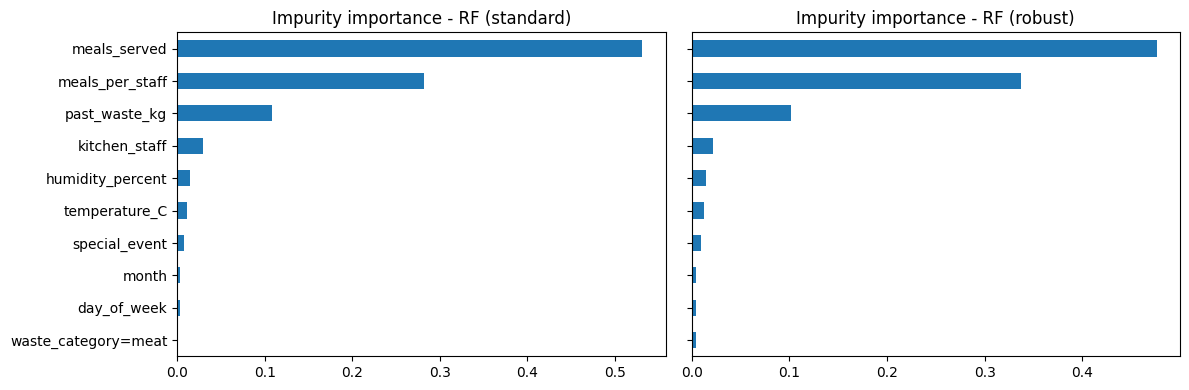


Permutation importance (kenaikan MAE jika fitur diacak) - standard
meals_served           7.253
past_waste_kg          5.345
meals_per_staff        1.296
special_event          0.626
humidity_percent       0.143
temperature_C          0.132
day_of_week            0.031
waste_category=MEAT    0.009

Permutation importance (kenaikan MAE jika fitur diacak) - robust
meals_served            6.588
past_waste_kg           5.274
meals_per_staff         2.189
special_event           0.713
temperature_C           0.152
humidity_percent        0.123
waste_category=dairy    0.017
day_of_week             0.009


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, (m, _)) in zip(axes, final_models.items()):
    imp = pd.Series(m.feature_importances_, index=FINAL[name][0].columns).sort_values().tail(10)
    imp.plot.barh(ax=ax, title=f"Impurity importance - RF ({name})")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "rf_feature_importance.png", dpi=120); plt.show()

for name, (m, _) in final_models.items():
    Xte, yte = FINAL[name][2], FINAL[name][3]
    pi = permutation_importance(m, Xte, yte, scoring="neg_mean_absolute_error",
                                n_repeats=10, random_state=SEED, n_jobs=-1)
    top = pd.Series(pi.importances_mean, index=Xte.columns).sort_values(ascending=False).head(8)
    print(f"\nPermutation importance (kenaikan MAE jika fitur diacak) - {name}")
    print(top.round(3).to_string())

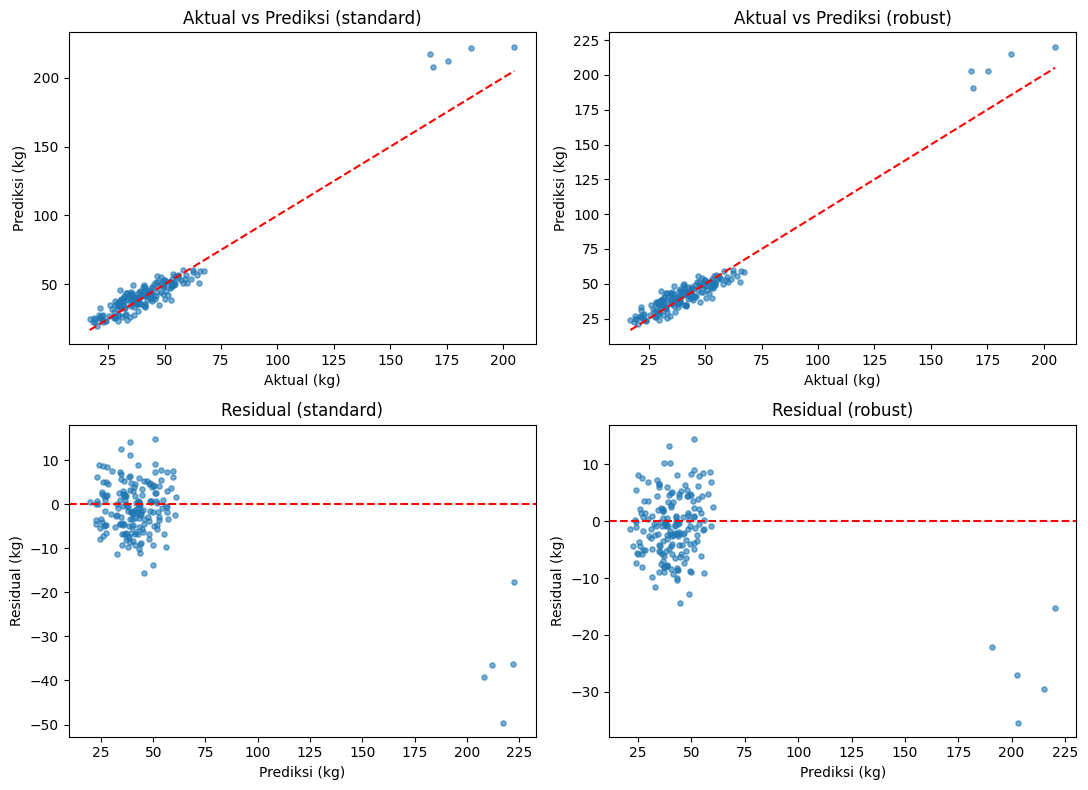

[standard] MAE meals<=1000: 4.41 (n=178) | meals>1000: 35.85 (n=5)
[robust] MAE meals<=1000: 4.34 (n=178) | meals>1000: 25.86 (n=5)


In [13]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for j, (name, (m, pred)) in enumerate(final_models.items()):
    yte = FINAL[name][3]
    axes[0, j].scatter(yte, pred, s=14, alpha=0.6)
    lim = [yte.min(), yte.max()]
    axes[0, j].plot(lim, lim, "r--"); axes[0, j].set_title(f"Aktual vs Prediksi ({name})")
    axes[0, j].set_xlabel("Aktual (kg)"); axes[0, j].set_ylabel("Prediksi (kg)")
    axes[1, j].scatter(pred, yte - pred, s=14, alpha=0.6); axes[1, j].axhline(0, color="r", ls="--")
    axes[1, j].set_title(f"Residual ({name})")
    axes[1, j].set_xlabel("Prediksi (kg)"); axes[1, j].set_ylabel("Residual (kg)")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "rf_actual_vs_pred.png", dpi=120); plt.show()

# error pada baris dengan meals_served ekstrem (>1000) vs normal
for name, (m, pred) in final_models.items():
    Xte, yte = FINAL[name][2], FINAL[name][3]
    ext = Xte["meals_served"] > 1000
    print(f"[{name}] MAE meals<=1000: {mean_absolute_error(yte[~ext], pred[~ext.values]):.2f} (n={int((~ext).sum())})"
          f" | meals>1000: {mean_absolute_error(yte[ext], pred[ext.values]):.2f} (n={int(ext.sum())})")